## Explorative Data Analysis

In [31]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
from matplotlib.patches import Patch

# Directory
BASE_DIR = Path.cwd()
print(BASE_DIR) 

PROCESSED_DIR = BASE_DIR / "data" / "processed"
print(PROCESSED_DIR)

df = pd.read_csv(PROCESSED_DIR / "movies_clean.csv")

c:\Users\Utente\Documents\Francesca\UNIVERSITA'\SOCIAL MEDIA\PROGETTO\movie-critics-vs-audience
c:\Users\Utente\Documents\Francesca\UNIVERSITA'\SOCIAL MEDIA\PROGETTO\movie-critics-vs-audience\data\processed


### Check summary statistics and distribution for year and runtime
First, I computed the upper bound using the IQR rule and found out 66 potential outliers. After checking them I could affirm that those films have actually a long duration and are not values that need to be taken out. The distribution is therefore slightly right-tailed. There is just one outlier in the left tail: a documentary that is 60 minutes long.

In [32]:
df[["year","runtime"]].describe()

,year,runtime
count,3398.000000,3398.000000
mean,2009.772513,109.819011
std,6.448253,17.728015
min,1927.000000,60.000000
25%,2005.000000,97.000000
50%,2010.000000,107.000000
75%,2015.000000,120.000000
max,2020.000000,223.000000


In [33]:
Q1 = df["runtime"].quantile(0.25)
Q3 = df["runtime"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers_runtime = df[
    (df["runtime"] < lower_bound) |
    (df["runtime"] > upper_bound)
]

print("Potential Outliers:", len(outliers_runtime))

IQR: 23.0
Lower bound: 62.5
Upper bound: 154.5
Potential Outliers: 66


In [34]:
outliers_runtime[
    ["movie_title", "runtime", "year"]
].sort_values("runtime", ascending=False)

,movie_title,runtime,year
1208,Gods and Generals,223.0,2003
1220,Gone With the Wind,222.0,1939
2876,The Irishman,209.0,2019
2915,The Lord of the Rings: The Return of the King,200.0,2003
3096,Titanic,195.0,1997
...,...,...,...
2977,The Revenant,156.0,2015
469,Avatar,155.0,2009
797,Cold Mountain,155.0,2003
1760,"Lust, Caution",155.0,2007


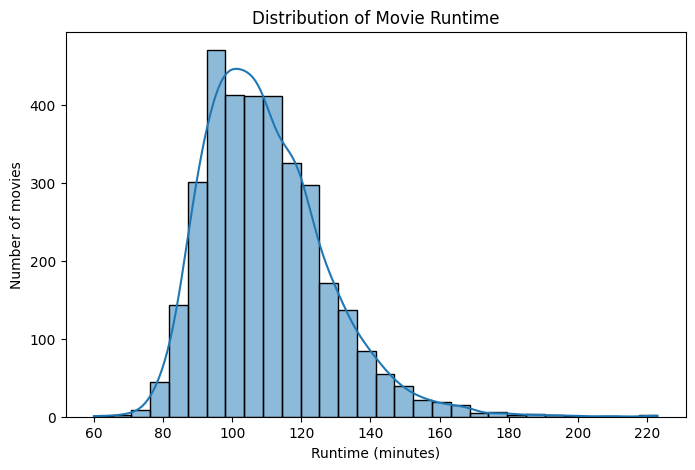

In [35]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="runtime",
    bins=30,
    kde=True
)

plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of movies")
plt.title("Distribution of Movie Runtime")

plt.show()

Then, I studied year distribution and noticed that the distribution is left-tailed and the majority of observations are concentrated in the timespan from 2000 to 2020. The graph shows very few old films and many recent ones. This is partly due to the dataset, but it could  also be the result of the threshold of ≥100 reviews and ≥100 ratings, which favors more recent and more famous films.

In [36]:
df["year"].value_counts().sort_index()

year
1927      1
1939      2
1960      1
1964      1
1968      1
1977      1
1979      1
1980      1
1982      2
1984      1
1990      1
1991      2
1992      1
1993      2
1994      3
1997      2
1998      8
1999     44
2000     82
2001    108
2002    145
2003    165
2004    168
2005    170
2006    178
2007    185
2008    161
2009    175
2010    170
2011    174
2012    165
2013    182
2014    170
2015    182
2016    185
2017    182
2018    192
2019    141
2020     43
Name: count, dtype: int64

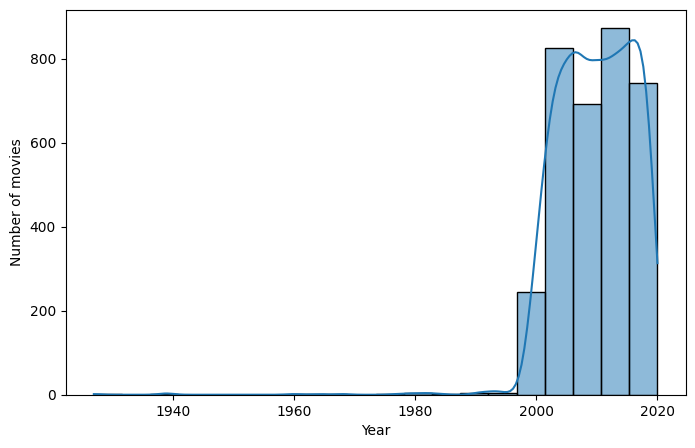

In [37]:
plt.figure(figsize=(8, 5))

sns.histplot(df["year"], bins=20, kde = True)
plt.xlabel("Year")
plt.ylabel("Number of movies")
plt.show()

### D variable inspection
After analyzing D distribution I can state it is approximately bell-shaped and centred near zero, with a slightly heavier right tail

In [38]:
df[["D"]].describe()

,D
count,3398.000000
mean,1.902590
std,18.549163
min,-79.000000
25%,-11.000000
50%,-0.500000
75%,14.000000
max,71.000000


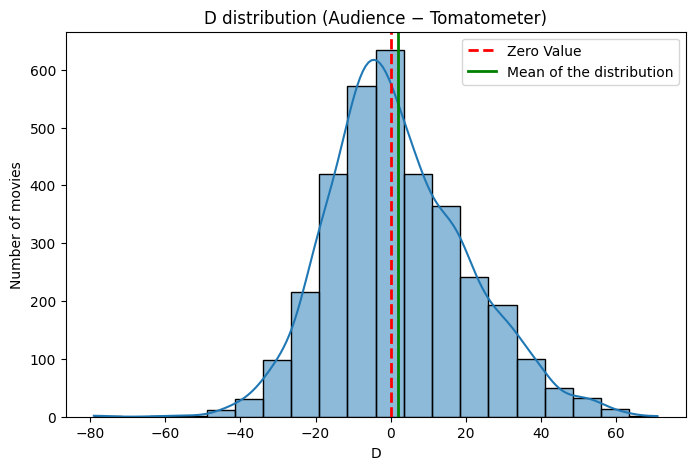

In [25]:
mean_D = np.mean(df['D'])

plt.figure(figsize=(8, 5))

sns.histplot(df["D"], bins=20, kde = True)
plt.xlabel("D")
plt.ylabel("Number of movies")
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label = 'Zero Value')
plt.axvline(x= mean_D, color='green', linestyle='-', linewidth=2, label = 'Mean of the distribution')
plt.title('D distribution (Audience − Tomatometer)')
plt.legend()
plt.show()

I also inspected the extremes, taking into account that:

D < 0 → critics rating is higher than audiance

D > 0 → audiance rating is higher than critics

D = 0 → similar rating

In [26]:
# highest D
nlargest = df.nlargest(10, "D")

# lowest D
nsmallest = df.nsmallest(10, "D")

cols_show = ["movie_title", "genres", "year", "tomatometer_rating", "audience_rating", "D"]
print("highest D:")
print(df.nlargest(10, "D")[cols_show])

print("\nlowest D:")
print(df.nsmallest(10, "D")[cols_show])

highest D:
                     movie_title  \
914   Diary of a Mad Black Woman   
1369                  House of D   
936                     Dolittle   
1694      The Life of David Gale   
2552                     Step Up   
526            Because I Said So   
2399                       Shaft   
2133                  Peppermint   
554               Beyond Borders   
1171                  Gemini Man   

                                                 genres  year  \
914                                              Comedy  2005   
1369                                              Drama  2004   
936   Action & Adventure, Comedy, Science Fiction & ...  2020   
1694                          Drama, Mystery & Suspense  2003   
2552                                              Drama  2006   
526                              Comedy, Drama, Romance  2007   
2399                         Action & Adventure, Comedy  2019   
2133             Action & Adventure, Mystery & Suspense  2018   
554    

In [27]:
q10 = df["D"].quantile(0.10)
q90 = df["D"].quantile(0.90)

print("10th percentile:", q10)
print("90th percentile:", q90) #group thresholds

df["group"] = "middle"
df.loc[df["D"] <= q10, "group"] = "audience_lower"   
df.loc[df["D"] >= q90, "group"] = "audience_higher"  
print(df["group"].value_counts())

10th percentile: -20.0
90th percentile: 27.0
group
middle             2681
audience_lower      359
audience_higher     358
Name: count, dtype: int64


In [28]:
df["content_rating"].value_counts() #NC17 has few values so it is left out in the comparison, for regression I will merge it to R

content_rating
R        1581
PG-13    1251
PG        406
NR         91
G          61
NC17        8
Name: count, dtype: int64

In [29]:
#  text stays selectable and sharp in the PDF
mpl.rcParams["pdf.fonttype"] = 42

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")

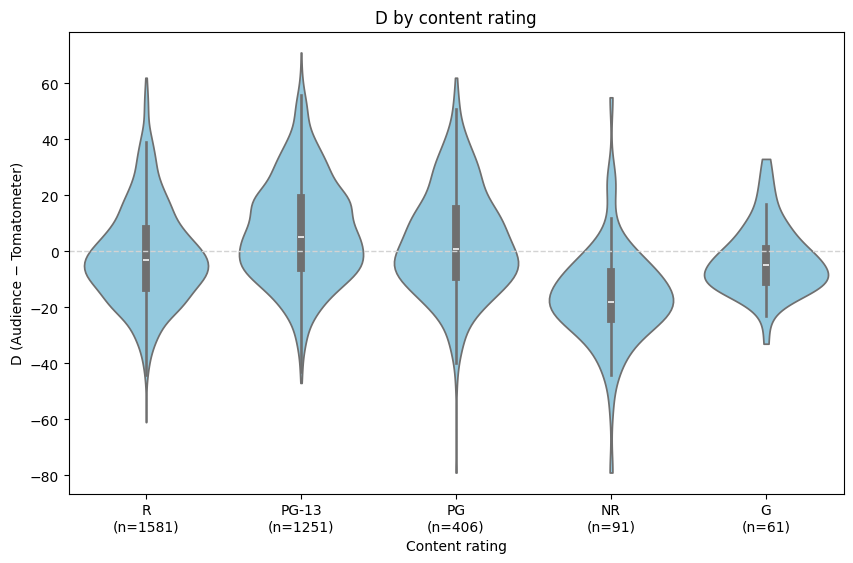

In [30]:
df_plot = df[df["content_rating"] != "NC17"]
counts = df_plot["content_rating"].value_counts()
order = counts.index
labels = [f"{c}\n(n={counts[c]})" for c in order]

fig, ax = plt.subplots(figsize=(10, 6))

# Violin plot
sns.violinplot(
    data=df_plot, x="content_rating", y="D", order=order,
    color="skyblue", inner="box", cut=0, density_norm="width", ax=ax
)

ax.set_xticks(range(len(order)))
ax.set_xticklabels(labels)
plt.axhline(0, linestyle="--", linewidth=1, color="lightgrey")
plt.xlabel("Content rating")
plt.ylabel("D (Audience − Tomatometer)")
plt.title("D by content rating")

FIG_DIR = BASE_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
save_fig(fig, "mean_D_by_content")
plt.show()

Content rating is based on MPAA in the USA:
G (General Audiences), PG (Parental Guidance Suggested), PG-13 (Parents Strongly Cautioned), R (Restricted), NC-17 (No One 17 and Under Admitted), NR (Not Rated).

NR has a clearly negative median (around −18): critics are much more generous than the audience for unrated films.

PG-13 has a positive median (around +5), and PG is close to 0; here, the audience tends to be slightly more generous than the critics.

R and G sit just below zero.

Outliers are more numerous on the positive side for R and PG-13, but they also appear on the negative side.

### Managing multi-genre films
"Keeping only the first genre" has a flaw: for example, a "Comedy, Romance" film would end up under Comedy and Romance would disappear, while Action & Adventure would absorb all action films regardless of other genres. The categories would be skewed.

In [39]:
df["genres"].str.split(", ").str[0].value_counts()

genres
Action & Adventure           944
Drama                        944
Comedy                       866
Art House & International    188
Horror                       134
Documentary                  110
Animation                    107
Mystery & Suspense            64
Classics                      12
Kids & Family                 12
Science Fiction & Fantasy     10
Musical & Performing Arts      3
Cult Movies                    2
Romance                        1
Western                        1
Name: count, dtype: int64

In [40]:
is_sorted = df["genres"].apply(lambda s: s.split(", ") == sorted(s.split(", ")))
print(is_sorted.mean()) # genres are ordered alphabetically and not according to their importance

0.9861683343143025


In [41]:
genre_dummies = df["genres"].str.get_dummies(sep=", ")
print(genre_dummies.sum().sort_values(ascending=False))

Drama                        1953
Comedy                       1206
Action & Adventure            944
Mystery & Suspense            741
Science Fiction & Fantasy     528
Romance                       385
Horror                        285
Kids & Family                 283
Art House & International     231
Animation                     198
Documentary                   135
Musical & Performing Arts     115
Special Interest               97
Western                        29
Sports & Fitness               28
Classics                       26
Television                     14
Cult Movies                     4
Faith & Spirituality            3
Gay & Lesbian                   1
dtype: int64


In [42]:
# Genres to keep
MIN_FILMS = 100   # minimum number of movies per genre

genre_counts = genre_dummies.sum()
kept = genre_counts[genre_counts >= MIN_FILMS].index.tolist()
dropped = genre_counts[genre_counts < MIN_FILMS]

print("Kept genres:", kept)
print("Dropped genres:\n", dropped.sort_values(ascending=False))

# movies that have none of the kept genres (they would have all dummies = 0)
n_no_kept = (genre_dummies[kept].sum(axis=1) == 0).sum()
print("\nMovies with no kept genre:", n_no_kept)

# Summary table of D by genre
rows = []
for g in kept:
    d = df.loc[genre_dummies[g] == 1, "D"]
    rows.append({
        "genre": g,
        "n": len(d),
        "mean_D": d.mean(),
        "median_D": d.median(),
        "se": d.std() / len(d) ** 0.5   # standard error of the mean
    })

genre_table = pd.DataFrame(rows).sort_values("mean_D").reset_index(drop=True)
print(genre_table.round(2))


Kept genres: ['Action & Adventure', 'Animation', 'Art House & International', 'Comedy', 'Documentary', 'Drama', 'Horror', 'Kids & Family', 'Musical & Performing Arts', 'Mystery & Suspense', 'Romance', 'Science Fiction & Fantasy']
Dropped genres:
 Special Interest        97
Western                 29
Sports & Fitness        28
Classics                26
Television              14
Cult Movies              4
Faith & Spirituality     3
Gay & Lesbian            1
dtype: int64

Movies with no kept genre: 1
                        genre     n  mean_D  median_D    se
0                 Documentary   135   -8.98      -8.0  0.99
1   Art House & International   231   -8.07      -9.0  0.82
2                   Animation   198   -1.66      -4.0  0.96
3                      Horror   285    0.07       0.0  1.15
4                       Drama  1953    1.00      -1.0  0.41
5               Kids & Family   283    1.12      -1.0  0.98
6   Musical & Performing Arts   115    1.95      -1.0  1.44
7          Mys

Movies after removing no-kept-genre case: 3397


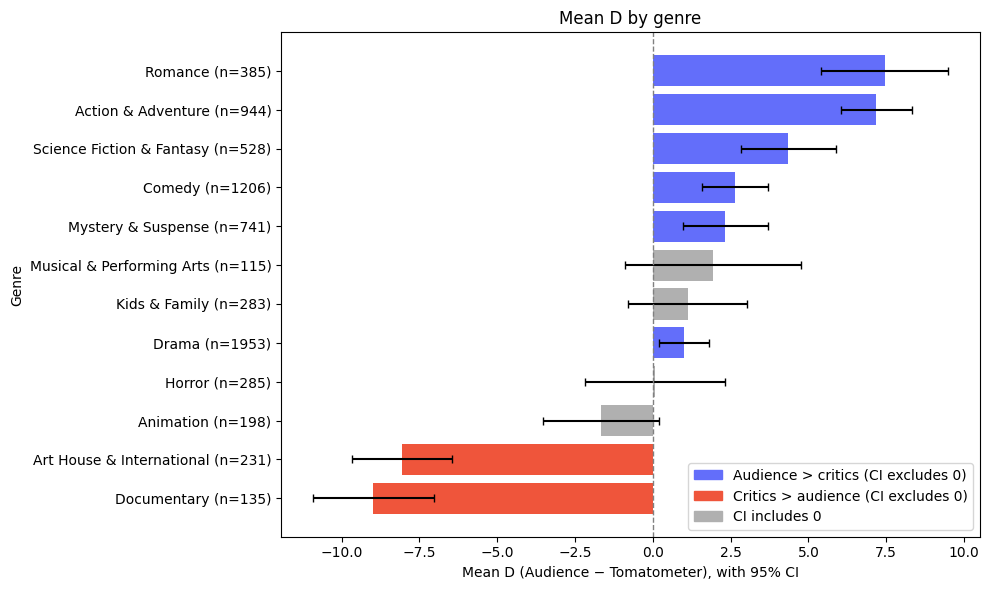

      period     n  mean_D    std     ci
0      <1980     8   -3.25   4.56   3.16
1      1980s     4   -7.00  13.24  12.98
2      1990s    63    2.49  13.34   3.29
3      2000s  1537    6.60  18.16   0.91
4  2010-2020  1785   -2.12  18.15   0.84


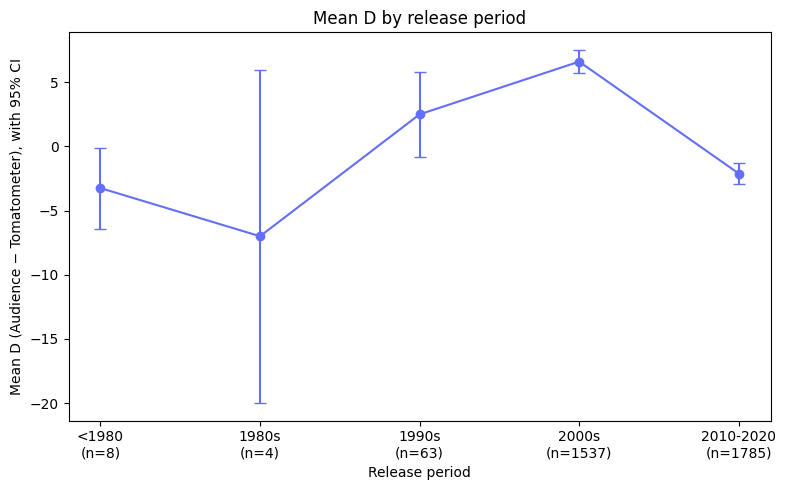

Pearson r = 0.085 | Spearman rho = 0.108


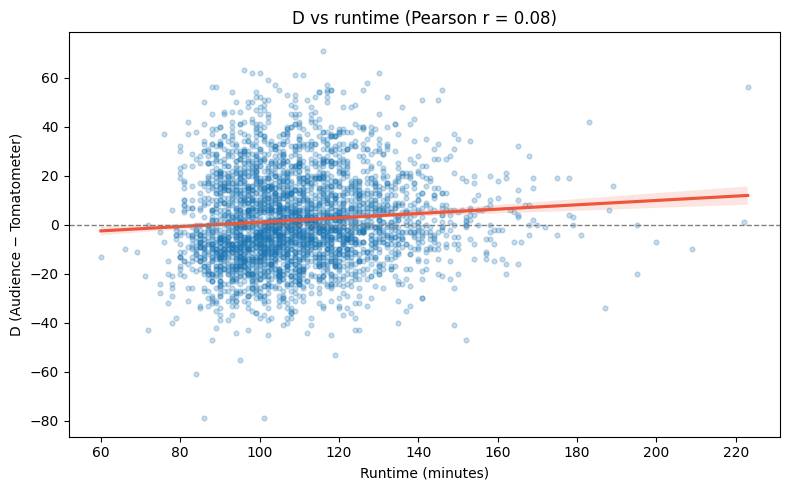

In [ ]:
# Setup
FIG_DIR = BASE_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

# remove the single movie with no kept genre
mask = genre_dummies[kept].sum(axis=1) > 0
df = df[mask]
genre_dummies = genre_dummies[mask]
print("Movies after removing no-kept-genre case:", len(df))   # expected 3397

# 1. Mean D by genre (colored by CI) with error bars
genre_table["ci"] = 1.96 * genre_table["se"]
# the 95% CI excludes 0 when |mean| > ci
genre_table["clear"] = genre_table["mean_D"].abs() > genre_table["ci"]

def pick_color(row):
    if not row["clear"]:
        return "#B0B0B0"          # grey: CI includes 0
    return "#636EFA" if row["mean_D"] > 0 else "#EF553B"

colors = genre_table.apply(pick_color, axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(genre_table["genre"], genre_table["mean_D"],
        xerr=genre_table["ci"], color=colors, capsize=3)
ax.axvline(0, linestyle="--", linewidth=1, color="grey")

ax.set_yticks(range(len(genre_table)))
ax.set_yticklabels([f"{g} (n={n})" for g, n in zip(genre_table["genre"], genre_table["n"])])

ax.set_xlabel("Mean D (Audience − Tomatometer), with 95% CI")
ax.set_ylabel("Genre")
ax.set_title("Mean D by genre")
ax.legend(handles=[
    Patch(color="#636EFA", label="Audience > critics (CI excludes 0)"),
    Patch(color="#EF553B", label="Critics > audience (CI excludes 0)"),
    Patch(color="#B0B0B0", label="CI includes 0"),
], loc="lower right")
plt.tight_layout()
save_fig(fig, "mean_D_by_genre")
plt.show()

# 2. Mean D by period 
bins = [1900, 1979, 1989, 1999, 2009, 2020]
labels = ["<1980", "1980s", "1990s", "2000s", "2010-2020"]
df["period"] = pd.cut(df["year"], bins=bins, labels=labels)

period_table = (
    df.groupby("period", observed=True)["D"]
      .agg(n="count", mean_D="mean", std="std")
      .reset_index()
)
period_table["ci"] = 1.96 * period_table["std"] / period_table["n"] ** 0.5
print(period_table.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(range(len(period_table)), period_table["mean_D"],
            yerr=period_table["ci"], fmt="-o", capsize=4, color="#636EFA")

ax.set_xticks(range(len(period_table)))
ax.set_xticklabels([f"{p}\n(n={n})" for p, n in zip(period_table["period"], period_table["n"])])
ax.set_xlabel("Release period")
ax.set_ylabel("Mean D (Audience − Tomatometer), with 95% CI")
ax.set_title("Mean D by release period")
plt.tight_layout()
save_fig(fig, "mean_D_by_period")
plt.show()

# 3. D vs runtime
pearson = df["runtime"].corr(df["D"])
spearman = df["runtime"].corr(df["D"], method="spearman")
print(f"Pearson r = {pearson:.3f} | Spearman rho = {spearman:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=df, x="runtime", y="D",
            scatter_kws={"alpha": 0.25, "s": 12},
            line_kws={"color": "#EF553B"}, ax=ax)
ax.axhline(0, linestyle="--", linewidth=1, color="grey")
ax.set_xlabel("Runtime (minutes)")
ax.set_ylabel("D (Audience − Tomatometer)")
ax.set_title(f"D vs runtime (Pearson r = {pearson:.2f})")
plt.tight_layout()
save_fig(fig, "D_vs_runtime")
plt.show()

### Mean D by genre
Genres where the audience is more generous than critics: Romance (+7.5) and Action & Adventure (+7.2), followed by Science Fiction & Fantasy (+4.4). The confidence intervals for these three do not include zero.

Genres where critics are more generous than the audience: Documentary (−9.0) and Art House & International (−8.1), with intervals far removed from zero.

Virtually no gap: Horror (0.07), Animation, Kids & Family, and Musical & Performing Arts have intervals that cross zero; thus, for these genres, one cannot say that D differs from zero. Drama (+1.0) is just above zero, but the effect is minimal.

This picture is consistent with what was observed for the 10 films with the highest D values ​​(comedies, action, commercial romantic dramas) and with the negative D value associated with the "NR" content rating (independent films, foreign films, documentaries). 
One question remains: regression analysis will reveal how much of this pattern is truly attributable to genre versus runtime, release year, or content rating.

### Mean D by release period
Mean D changes sign across periods: it is positive for the 2000s (about +6.5, audience more generous than critics) and slightly negative for 2010-2020 (about -2, critics more generous). The 95% CIs of these two periods exclude zero. The earlier periods (<1980, 1980s, 1990s) have very few films (n = 8, 4, 63), so their means and very wide intervals are not informative, and I do not interpret them. 2000s and 2010-2020 account for almost all the observations, so the relationship between year and D is not monotonic. This is a descriptive pattern, and I do not claim any explanation: it may depend on how audience ratings were collected over time, or on the composition of genres in each period, which the regression will help to clarify.

### D vs runtime
The relationship between runtime and D is very weak (Pearson r = 0.08): the fitted line rises slightly, but the points form a wide cloud around it at every runtime, so runtime explains less than 1% of the variance of D. The correlation is statistically detectable with this sample size, but it is practically negligible. The confidence band widens above 160 minutes, where films are few, and the few very long films have a large influence on the slope. Runtime alone does not seem to explain the gap between critics and audience; its role will be checked in the regression, together with genre and content rating.

Note:
- An "Action/Comedy" film counts towards both bars; therefore, the groups are not independent, as previously mentioned.

- Mean and median values ​​diverge for certain genres.

- I only included films with at least 100 audience votes. In niche genres (e.g., Documentary, Art House), only the most well-known films remain, so they may not be representative of the genre as a whole. This should be noted as a limitation.